# DDPG and TD3 parameter study

## Purpose

This notebook summarizes a parameter study of sequential DDPG and sequential TD3 on three feeders, as input for choosing future default settings.
All results use the validation split; the held-out test split is unused.
The notebook does not change any default.

The seven configurations are a subset of about 80 TD3 and 30 DDPG configuration–feeder combinations in the full exploration.
They are settings of two algorithms and a selection of the tested variants.
The letters are names only and indicate neither rank nor experiment order.

| Label | Summary |
|---|---|
| DDPG-A | Existing sequential DDPG |
| DDPG-B | DDPG-A with batch 256 |
| DDPG-C | DDPG-A with tau 0.0025 |
| TD3-A | Original sequential TD3 recipe, 400/300 widths |
| TD3-B | TD3-A with slower actor, faster critic, broader exploration and a longer warm-up |
| TD3-C | TD3-B with exploration decaying from 0.04 to 0.01 p.u. |
| TD3-D | TD3-A with slower actor, broader exploration, longer warm-up, delay 4 and batch 512 |

The baseline and change tables give exact values.

## Common settings

**Control task.** Each day has 24 hourly decisions and starts with all regulators at the neutral position.
Executed positions persist from hour to hour within the day. The learner proposes one continuous ratio per regulator in 0.90–1.10 p.u.
The simulator executes the nearest of 33 tap positions (step 0.00625 p.u.; position 16 is neutral, 1.00 p.u.).

**Training data.** The original training set has 1000 distinct synthetic days.
Each hour applies one uniform random loading multiplier in 0.5–1.5 to all loads of the feeder.
A budget of 4000 or 8000 training days is the number of episodes drawn from these 1000 days in shuffled passes, so each day repeats four or eight times.
The section "More distinct training days" covers a larger training set.

**Validation.** Each trained policy runs on the same 200 validation days of 24 hours, 4800 decisions per policy.
Tables and plots show the arithmetic mean over seeds 0, 1 and 2.
Means can hide differences between seeds; the feeder notes state seed agreement where relevant.

**Costs.** For monitored voltage measurements $v_1,\dots,v_M$ in p.u., the excursion outside the band is
$e_m = \max(0.95 - v_m, 0) + \max(v_m - 1.05, 0)$. Then

$$c_h = \frac{1}{M}\sum_{m=1}^{M} e_m^2, \qquad C_\text{voltage} = \sum_{h=0}^{23} c_h, \qquad C_\text{combined} = C_\text{voltage} + 10^{-5}\,S,$$

where $S$ is the number of executed tap steps in the day: position changes summed over regulators and hours, including the first move from neutral.
The hourly training reward is $-1000\,(c_h + 10^{-5} S_h)$, so the daily reward is $-1000\,C_\text{combined}$. The discount factor is 1.
Voltage cost sums hourly mean squared p.u. excursions. Combined cost adds the weighted tap-step penalty; it is a benchmark objective, not a monetary or energy cost.

**Interpretation.** Combined cost is the objective; lower is better.
Lower voltage cost and fewer tap steps are also preferable, and combined cost weighs the two.
A compliant hour has every monitored measurement inside 0.95–1.05 p.u. and a converged power flow; more compliant hours are better.
Compliance counts hours without excursion, and voltage cost measures excursion size, so the two can rank configurations differently.

**Feeders.** The number of controlled regulators and the voltage measurement convention differ by feeder:

| Feeder | Controlled regulators | Monitored voltages |
|---|---:|---|
| IEEE13 | 3 | line-to-ground, all initially live nodes |
| IEEE37std | 2 | line-to-line, three-phase pairs except the source bus |
| IEEE37mod | 5 | line-to-line, three-phase pairs except the source bus |

Cost levels differ between feeders. Do not compare costs across feeders as an algorithm ranking.

## DDPG-A baseline settings

DDPG-A is the existing sequential DDPG learner, with one critic and target networks ([Bai, Meng and Lee, 2026](https://ifac.papercept.net/conferences/conferences/IFAC26/program/IFAC26_ContentListWeb_3.html)).

| Setting | DDPG-A value |
|---|---|
| Actor | observation → 400 → 300 → one output per regulator; ReLU hidden layers with LayerNorm; tanh output |
| Critic (one) | state pathway 400 → 300 with LayerNorm and ReLU; actions enter through a linear 300-unit layer added to the state features; one further 300-unit layer (LayerNorm, ReLU) → value |
| Initialization | uniform fan-in bounds for hidden layers; output layers within ±0.003 |
| Optimizer | Adam; actor learning rate 0.0001; critic learning rate 0.001; critic weight decay 0 |
| Gradient clipping | norm 1 for actor and critic |
| Replay | capacity 1,000,000; batch 64, sampled without replacement within a batch |
| Target update | tau 0.001 after every learning step |
| Warm-up | uniform random physical actions for the first 20 days (480 interactions) |
| Learning start | interaction 64, when replay holds one batch (during the warm-up) |
| Updates | one critic, one actor and one target update per interaction from then on |
| Exploration after warm-up | each decision is uniform random with probability 0.10; otherwise actor output plus Gaussian noise |
| Noise scale | sigma 0.4 in raw actor units, multiplied by 0.99977 once per day, floor 0.15 |

**Noise units.** Raw actor units span −1 to 1 over 0.90–1.10 p.u., so 0.1 raw equals 0.01 p.u.
The noise starts at 0.4 raw (0.04 p.u.) with a floor of 0.15 raw (0.015 p.u.). The noisy proposal is clipped to the action range.
The noise scale decays once per day from day 1, including the 20 warm-up days, which use uniform actions instead of Gaussian noise.
It is about 0.159 raw (0.016 p.u.) at day 4000 and reaches the floor at day 4264.

**Batch size** is the number of replay transitions in one update. **Tau** is the fraction of the online weights mixed into the target weights at each target update.

## TD3-A baseline settings

TD3-A is the original sequential TD3 recipe. It uses canonical TD3 updates ([Fujimoto et al., 2018](https://proceedings.mlr.press/v80/fujimoto18a.html)) with the settings below.
Some settings differ from the paper and the author's code.

| Setting | TD3-A value |
|---|---|
| Actor | observation → 400 → 300 → one output per regulator; ReLU hidden layers; tanh output; no LayerNorm |
| Critics (two) | two independent branches, each (observation, action) → 400 → 300 → value; ReLU; no LayerNorm |
| Initialization | PyTorch default linear-layer initialization |
| Optimizer | Adam; actor and critic learning rates 0.0003 |
| Gradient clipping | none |
| Replay | capacity 1,000,000; batch 256, sampled with replacement |
| Target update | tau 0.005 at each target update |
| Warm-up | uniform random physical actions for the first 480 interactions (20 days) |
| Learning start | interaction 481 |
| Updates | both critics once per interaction; actor and all targets every 2 critic iterations (policy delay 2) |
| Exploration after warm-up | actor ratio plus Gaussian noise, sigma 0.01 p.u., constant |
| Target smoothing | Gaussian noise sigma 0.02 p.u., clipped to ±0.05 p.u., then target action clipped to 0.90–1.10 p.u. |

**TD3 mechanisms.**
*Twin critics:* the learning target uses the smaller of the two target-critic values.
*Delayed policy updates:* the actor and target networks update once per `policy delay` critic iterations. The delay counts learning steps and is independent of the hourly control interval.
*Target-policy smoothing:* the target action receives small clipped noise before the critics evaluate it. Target actions stay continuous; only executed actions are projected to tap positions.

**Warm-up** fills replay with random actions before the actor explores. **Exploration sigma** is the scale of the noise added to the actor's proposal during training.
Both learners store the executed ratio, after projection to a tap position, in replay.

**Shared settings.** Both baselines use discount factor 1, the reward above and a day that ends after hour 23.

## Changes from baseline

Each row lists all differences from the configuration's baseline, DDPG-A or TD3-A. All other settings match the baseline.

| Configuration | Changes from its baseline | Purpose |
|---|---|---|
| DDPG-B | batch 64 → 256; learning start therefore interaction 64 → 256 | Test whether larger batches reduce gradient noise. |
| DDPG-C | tau 0.001 → 0.0025 | Test whether faster target updates help. |
| TD3-B | actor LR 0.0003 → 0.0001; critic LR 0.0003 → 0.001; exploration 0.01 → 0.04 p.u.; warm-up 480 → 4800 interactions; learning start 481 → 4801 | Broader exploration; higher critic learning rate relative to the actor. |
| TD3-C | actor LR 0.0003 → 0.0001; critic LR 0.0003 → 0.001; exploration 0.01 → 0.04 p.u. at interaction 4801, decreasing linearly to 0.01 p.u. at interaction 96000, then constant to 192000; warm-up 480 → 4800; learning start 481 → 4801 | Test broad exploration early and less noise late. |
| TD3-D | actor LR 0.0003 → 0.0001; exploration 0.01 → 0.04 p.u.; warm-up 480 → 4800; learning start 481 → 4801; policy delay 2 → 4; batch 256 → 512. Critic LR stays 0.0003 | Test broader exploration with fewer, larger-batch actor updates. |

Interaction 96000 is the end of day 4000; interaction 192000 is the end of day 8000.

In [1]:
MEANS = {
    ("ieee13", "DDPG-A", 4000): (0.0009394064098066972, 0.0004621564098066973, 47.725, 183.66666666666666),
    ("ieee13", "DDPG-A", 8000): (0.000897901729224478, 0.0004565350625578113, 44.13666666666666, 121.0),
    ("ieee13", "DDPG-B", 4000): (0.0009035352172682429, 0.0004973352172682429, 40.620000000000005, 177.33333333333334),
    ("ieee13", "DDPG-B", 8000): (0.0008886174220694565, 0.000510884088736123, 37.77333333333333, 174.0),
    ("ieee13", "DDPG-C", 4000): (0.0009253428085370794, 0.0005126594752037461, 41.26833333333334, 177.66666666666666),
    ("ieee13", "DDPG-C", 8000): None,  # not run
    ("ieee13", "TD3-A", 4000): (0.012670241904705995, 0.012020491904705992, 64.97500000000001, 0.0),
    ("ieee13", "TD3-A", 8000): (0.007732147069573811, 0.006810913736240477, 92.12333333333333, 27.333333333333332),
    ("ieee13", "TD3-B", 4000): (0.0010408952603648393, 0.00045439526036483924, 58.65, 752.3333333333334),
    ("ieee13", "TD3-B", 8000): (0.0009230012513619003, 0.0004679345846952336, 45.50666666666667, 157.66666666666666),
    ("ieee13", "TD3-C", 4000): (0.0009876296517890735, 0.0004619629851224069, 52.56666666666666, 379.0),
    ("ieee13", "TD3-C", 8000): (0.0009164181876707228, 0.0004933015210040561, 42.31166666666667, 116.33333333333333),
    ("ieee13", "TD3-D", 4000): None,  # not run
    ("ieee13", "TD3-D", 8000): None,  # not run
    ("ieee37std", "DDPG-A", 4000): (0.005610286051447491, 0.005271819384780825, 33.846666666666664, 0.0),
    ("ieee37std", "DDPG-A", 8000): (0.005618200854905103, 0.005270184188238436, 34.80166666666667, 11.0),
    ("ieee37std", "DDPG-B", 4000): (0.0056470008432708135, 0.005271300843270814, 37.57, 23.666666666666668),
    ("ieee37std", "DDPG-B", 8000): (0.005657370736950252, 0.005270570736950252, 38.68, 36.0),
    ("ieee37std", "DDPG-C", 4000): (0.0055916873804720026, 0.005271687380472002, 32.0, 0.0),
    ("ieee37std", "DDPG-C", 8000): (0.0056709826797824115, 0.005270849346449079, 40.01333333333333, 65.33333333333333),
    ("ieee37std", "TD3-A", 4000): (0.0055916873804720026, 0.005271687380472002, 32.0, 0.0),
    ("ieee37std", "TD3-A", 8000): (0.0055916873804720026, 0.005271687380472002, 32.0, 0.0),
    ("ieee37std", "TD3-B", 4000): (0.0055916873804720026, 0.005271687380472002, 32.0, 0.0),
    ("ieee37std", "TD3-B", 8000): (0.005592565930127902, 0.0052702325967945675, 32.233333333333334, 17.333333333333332),
    ("ieee37std", "TD3-C", 4000): (0.005592559392260589, 0.0052716593922605874, 32.09, 0.0),
    ("ieee37std", "TD3-C", 8000): (0.005648932219460432, 0.005263765552793766, 38.51666666666667, 54.666666666666664),
    ("ieee37std", "TD3-D", 4000): (0.005590957868412492, 0.0052708245350791575, 32.01333333333333, 12.333333333333334),
    ("ieee37std", "TD3-D", 8000): (0.005591529412408018, 0.005270829412408018, 32.07, 23.333333333333332),
    ("ieee37mod", "DDPG-A", 4000): (0.005178762035739787, 0.003716162035739787, 146.26, 65.0),
    ("ieee37mod", "DDPG-A", 8000): (0.004877763578904589, 0.0036940469122379222, 118.37166666666667, 33.333333333333336),
    ("ieee37mod", "DDPG-B", 4000): (0.005952293217875079, 0.0038960265512084113, 205.62666666666667, 61.666666666666664),
    ("ieee37mod", "DDPG-B", 8000): None,  # not run
    ("ieee37mod", "DDPG-C", 4000): (0.005097967902229547, 0.003794401235562881, 130.35666666666665, 17.333333333333332),
    ("ieee37mod", "DDPG-C", 8000): (0.004767622131729697, 0.0036354887983963634, 113.21333333333332, 23.0),
    ("ieee37mod", "TD3-A", 4000): (0.03464644712146332, 0.03384644712146332, 80.0, 0.0),
    ("ieee37mod", "TD3-A", 8000): (0.03464644712146332, 0.03384644712146332, 80.0, 0.0),
    ("ieee37mod", "TD3-B", 4000): (0.02700527389375451, 0.026191473893754508, 81.38, 0.0),
    ("ieee37mod", "TD3-B", 8000): (0.02697707791308677, 0.026175877913086773, 80.12, 0.0),
    ("ieee37mod", "TD3-C", 4000): None,  # not run
    ("ieee37mod", "TD3-C", 8000): None,  # not run
    ("ieee37mod", "TD3-D", 4000): (0.019412333527539603, 0.018612333527539604, 80.0, 0.0),
    ("ieee37mod", "TD3-D", 8000): (0.008275988478164993, 0.004645088478164995, 363.09, 11.666666666666666),
}
EXPANDED = {  # 8000 training days on the 8000-day dataset
    ("ieee13", "DDPG-B"): (0.0008674270906950655, 0.0005223437573617321, 34.50833333333333, 146.0),
    ("ieee13", "TD3-C"): (0.0009122776185106514, 0.00047439428517731806, 43.788333333333334, 183.66666666666666),
    ("ieee37mod", "DDPG-C"): (0.00487345414346637, 0.003663770810133037, 120.96833333333332, 14.333333333333334),
    ("ieee37mod", "TD3-D"): (0.010083799969796596, 0.0062604166364632645, 382.33833333333337, 7.333333333333333),
}

In [2]:
import math

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.transforms import Bbox
from IPython.display import Markdown, display

LABELS = ["DDPG-A", "DDPG-B", "DDPG-C", "TD3-A", "TD3-B", "TD3-C", "TD3-D"]
BUDGETS = [4000, 8000]
BUDGET_COLORS = {4000: "#86b6ef", 8000: "#1c5cab"}  # One hue: lighter is fewer days.
ALGORITHM_COLORS = {"DDPG": "#2a78d6", "TD3": "#eb6834"}
MARKERS = {"A": "o", "B": "s", "C": "D", "D": "^"}
NAMES = {"ieee13": "IEEE13", "ieee37std": "IEEE37std", "ieee37mod": "IEEE37mod"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True})


def baseline(label):
    return "DDPG-A" if label.startswith("DDPG") else "TD3-A"


def show_table(feeder):
    """Show 14 rows: configuration x training days, with the change against its own baseline."""
    lines = ["| Configuration | Training days | Combined cost/day | vs own baseline | "
             "Voltage cost/day | Tap steps/day | Compliant hours (of 4800) |",
             "|---|---:|---:|---:|---:|---:|---:|"]
    for label in LABELS:
        for budget in BUDGETS:
            row = MEANS[(feeder, label, budget)]
            if row is None:
                lines.append(f"| {label} | {budget} | not run | | | | |")
                continue
            combined, voltage, steps, hours = row
            base = MEANS[(feeder, baseline(label), budget)]
            pct = 100 * (combined / base[0] - 1)
            change = "—" if label == baseline(label) else f"{pct:+.2f}%" if abs(pct) < 0.1 else f"{pct:+.1f}%"
            lines.append(f"| {label} | {budget} | {combined:.6g} | {change} | {voltage:.6g} | "
                         f"{steps:.1f} | {hours:.1f} |")
    display(Markdown("\n".join(lines)))


def cost_bars(feeder, log=False):
    """Grouped bars of mean combined cost: seven configurations, 4000 and 8000 days."""
    fig, ax = plt.subplots(figsize=(8.5, 3.9))
    width = 0.38
    for j, budget in enumerate(BUDGETS):
        for i, label in enumerate(LABELS):
            x = i + (j - 0.5) * width
            row = MEANS[(feeder, label, budget)]
            if row is None:
                ax.text(x, 0.02, "not run", transform=ax.get_xaxis_transform(), rotation=90,
                        ha="center", va="bottom", fontsize=8, color="#6f6e69")
                continue
            ax.bar(x, row[0], width * 0.92, color=BUDGET_COLORS[budget],
                   label=f"{budget} training days" if i == 0 else None)
    ax.set_xticks(range(len(LABELS)), LABELS)
    ax.set_ylabel("Combined cost per day")
    plain_linear_axis(ax.yaxis)
    if log:
        ax.set_yscale("log")
        ax.set_ylim(0.0005, None)
        plain_log_axis(ax.yaxis)
        ax.set_ylabel("Combined cost per day, log scale")
    ax.grid(axis="x", visible=False)
    fig.legend(frameon=False, ncol=2, loc="lower center", bbox_to_anchor=(0.5, -0.01))
    ax.set_title(f"{NAMES[feeder]}: mean combined validation cost, seeds 0–2 (lower is better)", fontsize=10)
    fig.tight_layout(rect=(0, 0.07, 1, 1))
    plt.show()


def groups(ax, points, pixels=9):
    """Join points whose markers overlap on screen into one shared label."""
    merged = []
    for x, y, label in points:
        px, py = ax.transData.transform((x, y))
        for group in merged:
            if any(abs(px - gx) <= pixels and abs(py - gy) <= pixels for gx, gy, _, _, _ in group):
                group.append((px, py, x, y, label))
                break
        else:
            merged.append([(px, py, x, y, label)])
    return merged


OFFSETS = [(8, 6), (8, -12), (-8, 6), (-8, -12), (10, 16), (10, -22), (-10, 16), (-10, -22),
           (0, 24), (0, -30), (24, 0), (-24, 0)]


def place_labels(ax, points, avoid=()):
    """Label each point group at the first offset clear of markers, earlier labels and ``avoid`` boxes."""
    fig = ax.figure
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    merged = groups(ax, points)
    taken = list(avoid)
    for group in merged:
        for px, py, *_ in group:
            taken.append(Bbox([[px - 6, py - 6], [px + 6, py + 6]]))
    box = ax.get_window_extent(renderer)
    for group in merged:
        x, y = group[0][2], group[0][3]
        text = ", ".join(sorted((g[4] for g in group), key=LABELS.index))
        for dx, dy in OFFSETS:
            note = ax.annotate(text, (x, y), xytext=(dx, dy), textcoords="offset points", fontsize=8.5,
                               ha="left" if dx >= 0 else "right", va="center")
            extent = note.get_window_extent(renderer)
            inside = box.contains(extent.x0, extent.y0) and box.contains(extent.x1, extent.y1)
            if inside and not any(extent.overlaps(t) for t in taken):
                taken.append(extent)
                break
            note.remove()
        else:
            note = ax.annotate(text, (x, y), xytext=(14, 18), textcoords="offset points", fontsize=8.5,
                               arrowprops={"arrowstyle": "-", "color": "#8a8984", "lw": 0.8})
            taken.append(note.get_window_extent(renderer))


def plain_linear_axis(axis):
    """Show full decimal values without a scientific offset."""
    axis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.10f}".rstrip("0").rstrip(".")))


def plain_log_axis(axis):
    """Show ordinary numbers on a logarithmic axis."""
    axis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    axis.set_minor_formatter(FuncFormatter(lambda v, _: f"{v:g}" if round(v / 10 ** math.floor(math.log10(v))) in (2, 3, 5) else ""))


def draw_points(ax, feeder, budget, labels):
    points = []
    for label in labels:
        row = MEANS[(feeder, label, budget)]
        if row is None:
            continue
        algorithm, variant = label.split("-")
        ax.scatter(row[2], row[1], s=60, marker=MARKERS[variant], color=ALGORITHM_COLORS[algorithm],
                   edgecolor="white", linewidth=1.2, zorder=3)
        points.append((row[2], row[1], label))
    return points


def tradeoff(feeder, logy=False, inset_without=()):
    """Two panels of mean voltage cost against mean tap steps, one per training budget.

    ``inset_without`` names configurations left out of an enlarged inset of the remaining points.
    """
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
    for ax, budget in zip(axes, BUDGETS):
        points = draw_points(ax, feeder, budget, LABELS)
        if logy:
            ax.set_yscale("log")
            plain_log_axis(ax.yaxis)
        else:
            plain_linear_axis(ax.yaxis)
        ax.margins(x=0.25, y=0.25)
        missing = [label for label in LABELS if MEANS[(feeder, label, budget)] is None]
        suffix = f" (not run: {', '.join(missing)})" if missing else ""
        ax.set_title(f"{budget} training days{suffix}", fontsize=10)
        ax.set_xlabel("Tap steps per day")
        ax.set_ylabel("Voltage cost per day" + (", log scale" if logy else ""))
        avoid = []
        if inset_without:
            ax.set_ylim(bottom=0)
            inset = ax.inset_axes([0.14, 0.3, 0.5, 0.6])
            inner = draw_points(inset, feeder, budget, [l for l in LABELS if l not in inset_without])
            inset.margins(x=0.3, y=0.3)
            inset.tick_params(labelsize=7.5)
            plain_linear_axis(inset.yaxis)
            inset.set_title("enlarged", fontsize=8, color="#52514e")
            ax.indicate_inset_zoom(inset, edgecolor="#8a8984")
            place_labels(inset, inner)
            fig.canvas.draw()
            avoid = [inset.get_tightbbox(fig.canvas.get_renderer())]
            points = [p for p in points if p[2] in inset_without]
        place_labels(ax, points, avoid)
    handles = [plt.Line2D([], [], marker=MARKERS[l.split("-")[1]], linestyle="", markersize=7,
                          color=ALGORITHM_COLORS[l.split("-")[0]], label=l) for l in LABELS]
    fig.legend(handles=handles, ncol=7, frameon=False, loc="lower center", bbox_to_anchor=(0.5, -0.02))
    fig.suptitle(f"{NAMES[feeder]}: voltage cost against tap movement, seed means (lower-left is better on both)",
                 fontsize=10)
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    plt.show()

## IEEE13

### Results table

Change is the ratio of the full-precision means to the same algorithm's baseline at the same training days.
Seed averaging gives fractional compliant hours.
Tap steps count position changes, so one hour can contribute several steps. "Not run" marks a configuration without saved runs on this feeder.

In [3]:
show_table("ieee13")

| Configuration | Training days | Combined cost/day | vs own baseline | Voltage cost/day | Tap steps/day | Compliant hours (of 4800) |
|---|---:|---:|---:|---:|---:|---:|
| DDPG-A | 4000 | 0.000939406 | — | 0.000462156 | 47.7 | 183.7 |
| DDPG-A | 8000 | 0.000897902 | — | 0.000456535 | 44.1 | 121.0 |
| DDPG-B | 4000 | 0.000903535 | -3.8% | 0.000497335 | 40.6 | 177.3 |
| DDPG-B | 8000 | 0.000888617 | -1.0% | 0.000510884 | 37.8 | 174.0 |
| DDPG-C | 4000 | 0.000925343 | -1.5% | 0.000512659 | 41.3 | 177.7 |
| DDPG-C | 8000 | not run | | | | |
| TD3-A | 4000 | 0.0126702 | — | 0.0120205 | 65.0 | 0.0 |
| TD3-A | 8000 | 0.00773215 | — | 0.00681091 | 92.1 | 27.3 |
| TD3-B | 4000 | 0.0010409 | -91.8% | 0.000454395 | 58.6 | 752.3 |
| TD3-B | 8000 | 0.000923001 | -88.1% | 0.000467935 | 45.5 | 157.7 |
| TD3-C | 4000 | 0.00098763 | -92.2% | 0.000461963 | 52.6 | 379.0 |
| TD3-C | 8000 | 0.000916418 | -88.1% | 0.000493302 | 42.3 | 116.3 |
| TD3-D | 4000 | not run | | | | |
| TD3-D | 8000 | not run | | | | |

### Combined cost

The vertical axis is logarithmic because TD3-A costs 8 to 14 times more than the other configurations.
Bars start at 0.0005, so bar length is not proportional to cost; the table gives exact values.

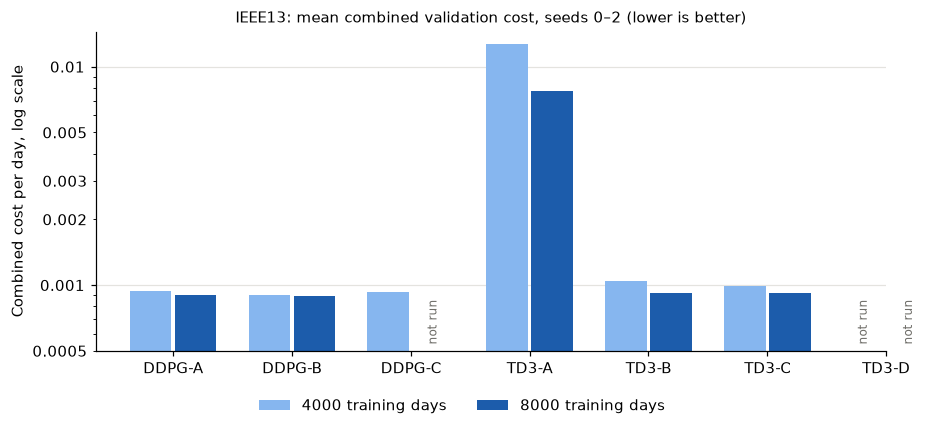

In [4]:
cost_bars("ieee13", log=True)

### Voltage cost and movement

Each point is a three-seed mean on linear axes. The inset enlarges the available configurations near the lower left; the grey rectangle marks its range.
Combined cost adds 10⁻⁵ per tap step, so ten extra steps per day add 0.0001, about one fifth of a typical IEEE13 voltage cost.

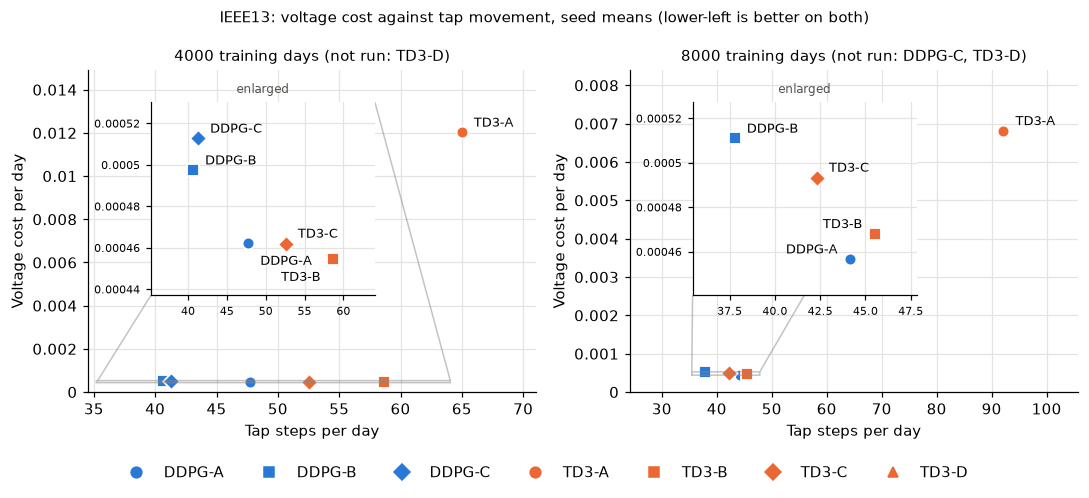

In [5]:
tradeoff("ieee13", inset_without=["TD3-A"])

**IEEE13 notes.**

- TD3-A has the highest cost at both budgets. TD3-B reduces it by 92% at 4000 days and 88% at 8000 days, on all three seeds.
- At 8000 days all other configurations lie between 0.000889 and 0.000923. DDPG-B is 1.0% below DDPG-A (two seeds lower, one higher). TD3-C is 0.7% below TD3-B (mixed across seeds).
- At 4000 days the differences are larger: DDPG-B −3.8% (no seed higher) and TD3-C −5.1% (one seed higher).
- TD3-B and TD3-C are 2–3% above DDPG-A at 8000 days.
- DDPG-B uses fewer tap steps than DDPG-A, with slightly higher voltage cost.
- TD3-B at 4000 days has the most compliant hours but not the lowest combined cost.
- TD3-D has no IEEE13 runs, and DDPG-C has runs to 4000 days only.

## IEEE37std

### Results table

In [6]:
show_table("ieee37std")

| Configuration | Training days | Combined cost/day | vs own baseline | Voltage cost/day | Tap steps/day | Compliant hours (of 4800) |
|---|---:|---:|---:|---:|---:|---:|
| DDPG-A | 4000 | 0.00561029 | — | 0.00527182 | 33.8 | 0.0 |
| DDPG-A | 8000 | 0.0056182 | — | 0.00527018 | 34.8 | 11.0 |
| DDPG-B | 4000 | 0.005647 | +0.7% | 0.0052713 | 37.6 | 23.7 |
| DDPG-B | 8000 | 0.00565737 | +0.7% | 0.00527057 | 38.7 | 36.0 |
| DDPG-C | 4000 | 0.00559169 | -0.3% | 0.00527169 | 32.0 | 0.0 |
| DDPG-C | 8000 | 0.00567098 | +0.9% | 0.00527085 | 40.0 | 65.3 |
| TD3-A | 4000 | 0.00559169 | — | 0.00527169 | 32.0 | 0.0 |
| TD3-A | 8000 | 0.00559169 | — | 0.00527169 | 32.0 | 0.0 |
| TD3-B | 4000 | 0.00559169 | +0.00% | 0.00527169 | 32.0 | 0.0 |
| TD3-B | 8000 | 0.00559257 | +0.02% | 0.00527023 | 32.2 | 17.3 |
| TD3-C | 4000 | 0.00559256 | +0.02% | 0.00527166 | 32.1 | 0.0 |
| TD3-C | 8000 | 0.00564893 | +1.0% | 0.00526377 | 38.5 | 54.7 |
| TD3-D | 4000 | 0.00559096 | -0.01% | 0.00527082 | 32.0 | 12.3 |
| TD3-D | 8000 | 0.00559153 | -0.00% | 0.00527083 | 32.1 | 23.3 |

### Combined cost

Bars start at zero. All means lie within 1.5% of each other, so the bars have almost equal height.

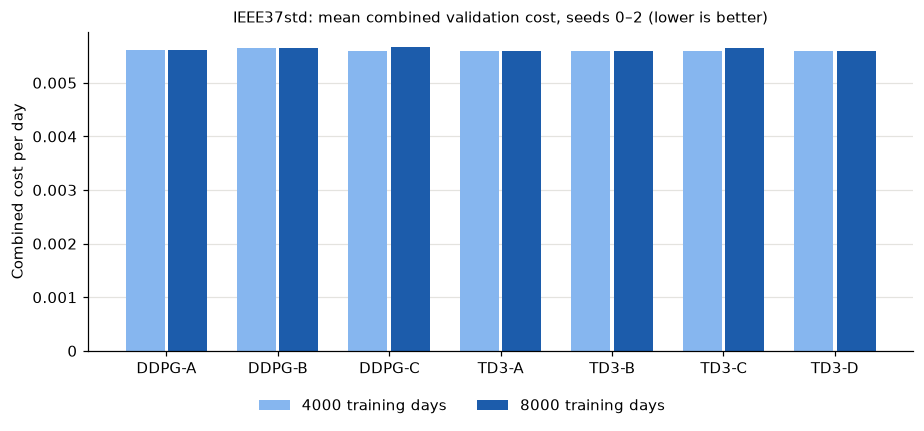

In [7]:
cost_bars("ieee37std")

### Voltage cost and movement

The vertical axis covers a narrow range and does not start at zero.
Points with overlapping markers share one label.

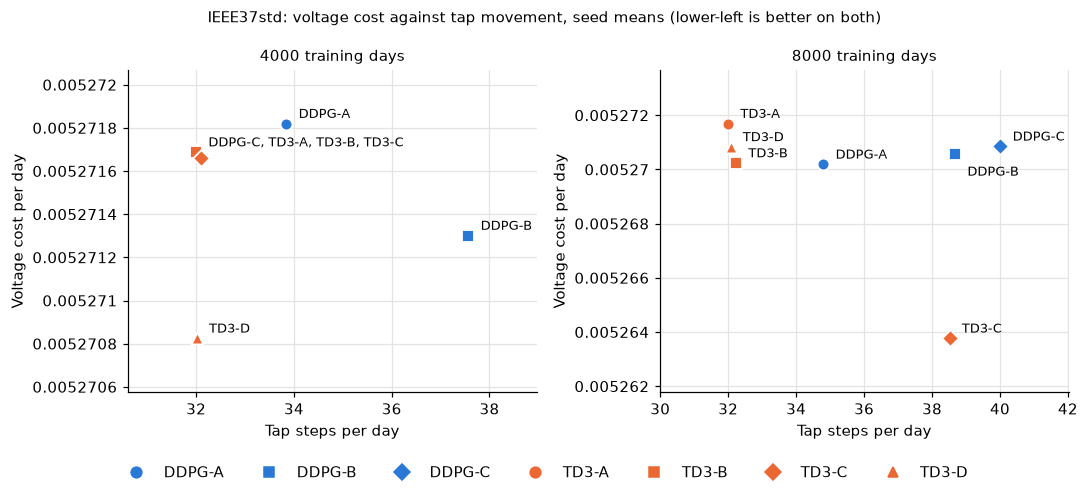

In [8]:
tradeoff("ieee37std")

**IEEE37std notes.**

- All 14 means lie between 0.005591 and 0.005671. Voltage costs differ by less than 0.2%, so most differences come from tap movement.
- Many runs hold both regulators at the top position in every validation hour, which gives 0.0055917 at 32 steps/day. TD3-A does this on every seed at both budgets.
- At 8000 days DDPG-B and DDPG-C cost 0.7% and 0.9% more than DDPG-A on all three seeds and use more tap steps.
- The configurations differ only slightly, and the results give little support for extra tuning on this feeder.

## IEEE37mod

### Results table

In [9]:
show_table("ieee37mod")

| Configuration | Training days | Combined cost/day | vs own baseline | Voltage cost/day | Tap steps/day | Compliant hours (of 4800) |
|---|---:|---:|---:|---:|---:|---:|
| DDPG-A | 4000 | 0.00517876 | — | 0.00371616 | 146.3 | 65.0 |
| DDPG-A | 8000 | 0.00487776 | — | 0.00369405 | 118.4 | 33.3 |
| DDPG-B | 4000 | 0.00595229 | +14.9% | 0.00389603 | 205.6 | 61.7 |
| DDPG-B | 8000 | not run | | | | |
| DDPG-C | 4000 | 0.00509797 | -1.6% | 0.0037944 | 130.4 | 17.3 |
| DDPG-C | 8000 | 0.00476762 | -2.3% | 0.00363549 | 113.2 | 23.0 |
| TD3-A | 4000 | 0.0346464 | — | 0.0338464 | 80.0 | 0.0 |
| TD3-A | 8000 | 0.0346464 | — | 0.0338464 | 80.0 | 0.0 |
| TD3-B | 4000 | 0.0270053 | -22.1% | 0.0261915 | 81.4 | 0.0 |
| TD3-B | 8000 | 0.0269771 | -22.1% | 0.0261759 | 80.1 | 0.0 |
| TD3-C | 4000 | not run | | | | |
| TD3-C | 8000 | not run | | | | |
| TD3-D | 4000 | 0.0194123 | -44.0% | 0.0186123 | 80.0 | 0.0 |
| TD3-D | 8000 | 0.00827599 | -76.1% | 0.00464509 | 363.1 | 11.7 |

### Combined cost

Bars start at zero. TD3-A costs about seven times more than DDPG at both budgets.

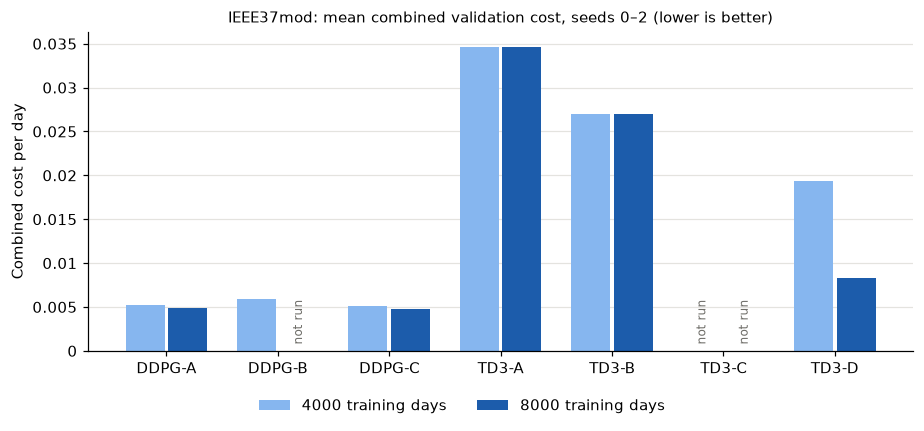

In [10]:
cost_bars("ieee37mod")

### Voltage cost and movement

The vertical axis is logarithmic because voltage costs span about a factor of ten. Points with overlapping markers share one label.

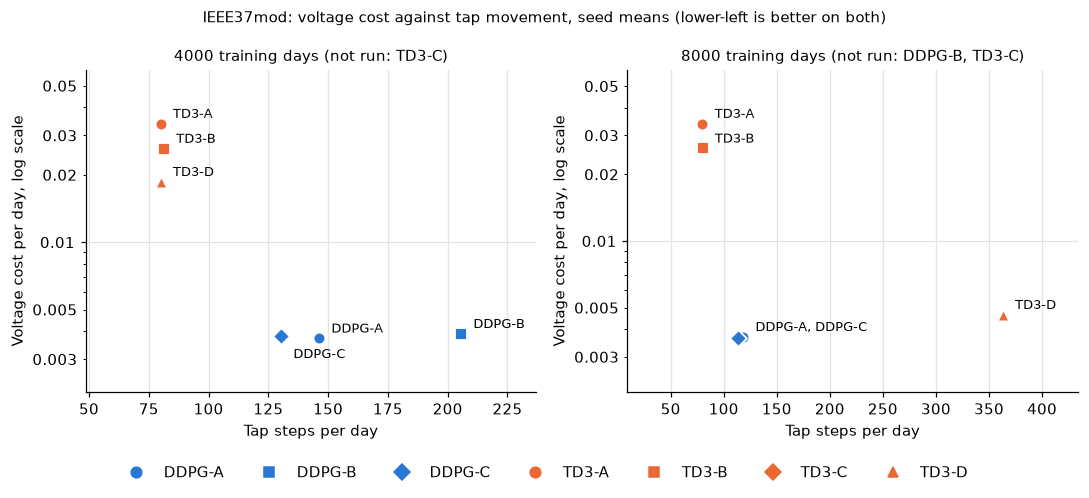

In [11]:
tradeoff("ieee37mod", logy=True)

**IEEE37mod notes.**

- TD3-A and TD3-B hold tap-limit positions in every validation hour on most seeds, at about 80 steps/day. Two positions occur: all five regulators at the top, or regulators 1–2 at the top and 3–5 at the bottom. The means average these seed results.
- TD3-D mostly holds tap limits at 4000 days. At 8000 days it changes positions from hour to hour on all three seeds, and its cost falls to 0.00828 at 363 steps/day.
- A configuration with the same settings except batch 256 (actor LR 0.0001, critic LR 0.0003, exploration 0.04 p.u., warm-up 4800, delay 4) costs 0.01683 at 8000 days. TD3-D is 51% lower, with all three seeds lower. At 4000 days the two differ by 0.2%.
- TD3-D costs 70% more than DDPG-A at 8000 days (all seeds higher) and uses about three times as many tap steps.
- DDPG-C is 2.3% below DDPG-A at 8000 days (two of three seeds lower). DDPG-B is 15% above DDPG-A at 4000 days on all seeds and has no 8000-day runs.
- TD3-C has no IEEE37mod runs.

## More distinct training days

This section compares two training sets at an equal number of episodes.
Four recipes train for 8000 episodes on the original 1000-day set and on an 8000-day set.
The 8000-day set extends the same load generator, so its first 1000 days equal the original set.
With 8000 days each day appears once; with 1000 days each day appears eight times.
Both use the same validation days and seeds 0–2. The main tables above exclude this comparison.

In [12]:
lines = ["| Feeder | Configuration | Combined cost/day, 1000-day set | Combined cost/day, 8000-day set | Change | "
         "Tap steps/day, 1000 → 8000-day set |", "|---|---|---:|---:|---:|---:|"]
for (feeder, label), expanded in EXPANDED.items():
    original = MEANS[(feeder, label, 8000)]
    lines.append(f"| {NAMES[feeder]} | {label} | {original[0]:.6g} | {expanded[0]:.6g} | "
                 f"{100 * (expanded[0] / original[0] - 1):+.1f}% | {original[2]:.1f} → {expanded[2]:.1f} |")
display(Markdown("\n".join(lines)))

| Feeder | Configuration | Combined cost/day, 1000-day set | Combined cost/day, 8000-day set | Change | Tap steps/day, 1000 → 8000-day set |
|---|---|---:|---:|---:|---:|
| IEEE13 | DDPG-B | 0.000888617 | 0.000867427 | -2.4% | 37.8 → 34.5 |
| IEEE13 | TD3-C | 0.000916418 | 0.000912278 | -0.5% | 42.3 → 43.8 |
| IEEE37mod | DDPG-C | 0.00476762 | 0.00487345 | +2.2% | 113.2 → 121.0 |
| IEEE37mod | TD3-D | 0.00827599 | 0.0100838 | +21.8% | 363.1 → 382.3 |

Change is the ratio of the two full-precision means.
Seed agreement: IEEE13 TD3-C, two seeds lower and one higher; IEEE13 DDPG-B, two lower and one slightly higher;
IEEE37mod TD3-D, two higher, one by 71%; IEEE37mod DDPG-C, all three higher by 0.4–5.3%.
The 8000-day set gives no consistent improvement in these runs.
The result comes from one realization of the larger set and does not rule out benefits from more data in general.

## Conclusions

The findings are exploratory: one synthetic load pattern, one validation split and three seeds. They do not establish statistical significance or convergence.

1. **IEEE13.** TD3-B reduces the TD3-A cost by about 90%. Other 8000-day differences within an algorithm are about 1% and mixed across seeds (DDPG-B vs DDPG-A, TD3-C vs TD3-B). These differences identify no clear best recipe, so the simpler recipe is a reasonable choice.
2. **IEEE37mod.** TD3-D is 51% below the same recipe with batch 256 at 8000 days, with all three seeds lower. TD3-D has higher cost and more tap steps than DDPG. TD3-A and TD3-B mostly stay at tap limits.
3. **IEEE37std.** All configurations lie within 1.5% of each other. The results give little support for extra tuning on this feeder.
4. **More distinct training days.** The 8000-day training set gives no consistent improvement.
5. **DDPG.** At 8000 days the DDPG changes are small on every feeder: at most 2.3% lower cost, and up to 0.9% higher on IEEE37std.

## Options for default settings

Each option below follows from the results above. The notebook does not select one.

| Question | Options | Considerations |
|---|---|---|
| DDPG default | Keep DDPG-A; or DDPG-B on IEEE13 and DDPG-C on IEEE37mod | Gains of 1–2% with mixed seeds; both slightly higher cost on IEEE37std. DDPG-B training time is about 1.6–1.8 times DDPG-A. |
| TD3 default, one recipe | TD3-B on all feeders | One recipe; 2.8% above DDPG-A on IEEE13 at 8000 days. Stays at tap limits on IEEE37mod. |
| TD3 default, feeder-specific | TD3-B or TD3-C on IEEE13; TD3-D on IEEE37mod | The batch 512 change gives a large, seed-consistent gain over the earlier delay 4, batch 256 recipe on IEEE37mod. It needs 8000 days; training time is about 1.3 times TD3-B there. |
| Training days | 4000 or 8000 | 8000 days roughly doubles training work. The largest gain is TD3-D on IEEE37mod (57%). IEEE13 TD3-A improves 39% but stays well above the tuned settings; TD3-B and TD3-C improve 11% and 7%. Other changes are smaller or absent. |
| Training set | 1000 days or 8000 distinct days | No consistent improvement from the larger set. |

Training times come from runs that shared one machine, twelve at a time with one thread each, so the ratios are approximate.
TD3-A and TD3-B have results on all three feeders. TD3-C as a common recipe would require its missing IEEE37mod runs; TD3-D would require its missing IEEE13 runs.
After the defaults are fixed, one held-out test evaluation can confirm them.

## Sources

Results come from two studies in this repository: the TD3 parameter exploration (26–27 September 2026) and the feeder-specific TD3 and DDPG tuning (27 September 2026).
This notebook contains their seed-mean validation results and runs no training, simulation or evaluation.

- Bai, Meng and Lee, "Voltage Control in Unbalanced Distribution Networks Using a Deep Deterministic Policy Gradient Reinforcement Learning Algorithm", IFAC World Congress 2026, Busan, paper WeA21.1: https://ifac.papercept.net/conferences/conferences/IFAC26/program/IFAC26_ContentListWeb_3.html
- Fujimoto, van Hoof and Meger, "Addressing Function Approximation Error in Actor-Critic Methods", ICML 2018: https://proceedings.mlr.press/v80/fujimoto18a.html